# Grocery Store Sales - A project into data cleaning, analysis, and visualisations
### A retail transaction dataset containing 500 transactions and 15 columns. It represents grocery store sales activity across different stores, locations, product categories, products, payment methods, customer ratings, discounts, and returns.
*Source: https://www.kaggle.com/datasets/arjunsinghgangwar/grocery-store-sales-dataset*

I believe that this dataset has potential to create great visualisations and analysis, with the sizeable amount of columns and data types it has. Potential questions I am aiming to explore are: **DO NOT FORGET TO PUT THIS IN**

## Initial Data Exploration

In [24]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# import matplotlib.cm
import scipy
import squarify

In [25]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

In [26]:
file_path = "grocery_store_data.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "arjunsinghgangwar/grocery-store-sales-dataset",
  file_path
)

print("First 5 records:", df.head())

First 5 records:   Transaction_ID        Date Store_ID Store_Location Product_Category  \
0       TXN00305  2024-02-22       S4      Bangalore            Dairy   
1       TXN00341  2024-07-22       S2          Delhi          Produce   
2       TXN00048  2025-03-30       S1        Chennai          Produce   
3       TXN00068  2024-12-03       S1        chennai           Bakery   
4       TXN00480  2024-07-09       S1         Mumbai          Produce   

             Product_Name  Quantity_Sold  Unit_Price  Discount_Percent  \
0   Paneer - Local Brand               5       94.76               5.0   
1         Tomato - Nestle             15       46.41               NaN   
2           Tomato - Amul              3       29.47              20.0   
3         Bun - Britannia             17       31.24              15.0   
4            Tomato - HUL             32       46.30               5.0   

   Total_Sales Payment_Mode  Customer_Rating    Employee_Name  \
0       450.11          UPI       

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    500 non-null    str    
 1   Date              500 non-null    str    
 2   Store_ID          500 non-null    str    
 3   Store_Location    500 non-null    str    
 4   Product_Category  500 non-null    str    
 5   Product_Name      500 non-null    str    
 6   Quantity_Sold     500 non-null    int64  
 7   Unit_Price        500 non-null    float64
 8   Discount_Percent  460 non-null    float64
 9   Total_Sales       485 non-null    float64
 10  Payment_Mode      500 non-null    str    
 11  Customer_Rating   470 non-null    float64
 12  Employee_Name     500 non-null    str    
 13  Contact           500 non-null    str    
 14  Returned          500 non-null    str    
dtypes: float64(4), int64(1), str(10)
memory usage: 58.7 KB


In [28]:
df[['Product_Category', 'Total_Sales']].head()

,Product_Category,Total_Sales
0,Dairy,450.11
1,Produce,696.15
2,Produce,70.73
3,Bakery,451.42
4,Produce,1407.52


## Data Cleaning

In [29]:
# Bringing back the information on the dataframe:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    500 non-null    str    
 1   Date              500 non-null    str    
 2   Store_ID          500 non-null    str    
 3   Store_Location    500 non-null    str    
 4   Product_Category  500 non-null    str    
 5   Product_Name      500 non-null    str    
 6   Quantity_Sold     500 non-null    int64  
 7   Unit_Price        500 non-null    float64
 8   Discount_Percent  460 non-null    float64
 9   Total_Sales       485 non-null    float64
 10  Payment_Mode      500 non-null    str    
 11  Customer_Rating   470 non-null    float64
 12  Employee_Name     500 non-null    str    
 13  Contact           500 non-null    str    
 14  Returned          500 non-null    str    
dtypes: float64(4), int64(1), str(10)
memory usage: 58.7 KB


As we can see from viewing the dataframe information, there are 500 entries, but not all of these entries have non-null values
for each and every column. Whereas the data types all seem adequate for their respective column, the non-null values can be problematic before we start our analysis.

The key outliers and how many values are missing are the columns of:

* 'Discount_Percent' is missing 40 values.
* 'Total_Sales' is missing 15 values.
* 'Customer_Rating' is missing 30 values.

I will now go through the methods that I will use to clean all of them, as well as reasoning.

### Cleaning the 'Total_Sales' column

As this column only consists of 15 missing values, and a total sales column would be hard to estimate for each product, I feel comfortable in dropping the missing rows here:

In [30]:
df = df.dropna(subset=['Total_Sales']) # using dropna to drop only the null rows from Total Sales

In [31]:
df.info()

<class 'pandas.DataFrame'>
Index: 485 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    485 non-null    str    
 1   Date              485 non-null    str    
 2   Store_ID          485 non-null    str    
 3   Store_Location    485 non-null    str    
 4   Product_Category  485 non-null    str    
 5   Product_Name      485 non-null    str    
 6   Quantity_Sold     485 non-null    int64  
 7   Unit_Price        485 non-null    float64
 8   Discount_Percent  449 non-null    float64
 9   Total_Sales       485 non-null    float64
 10  Payment_Mode      485 non-null    str    
 11  Customer_Rating   456 non-null    float64
 12  Employee_Name     485 non-null    str    
 13  Contact           485 non-null    str    
 14  Returned          485 non-null    str    
dtypes: float64(4), int64(1), str(10)
memory usage: 60.6 KB


As we can see above, now the total number of entries is 485 from the 15 removed, and 'Total_Sales' is in line with that.
'Discount_Percent' now only has 36 missing values, and 'Customer_Rating' now only has 29 missing values.

### Cleaning the 'Discount_Percent' column

My idea for cleaning this column, is that instead of removing these rows are there are a lot of rows, I will try to find similar discounts for these empty rows compared to others of the same of either the product name/unit price, or the broader product category. This should give a close or exact potential discount figure.

In [32]:
# To find the 36 rows where the values are missing
missing_discounts = df[df['Discount_Percent'].isnull()]
missing_discounts[['Transaction_ID', 'Product_Category', 'Product_Name', 'Unit_Price', 'Discount_Percent']].head(10)

,Transaction_ID,Product_Category,Product_Name,Unit_Price,Discount_Percent
1,TXN00341,Produce,Tomato - Nestle,46.41,NaN
52,TXN00006,Frozen Foods,Frozen Pizza - Nestle,166.34,NaN
85,TXN00224,Beverages,Green Tea - Patanjali,71.60,NaN
86,TXN00445,Beverages,Cola - HUL,47.75,NaN
99,TXN00111,Dairy,Yogurt - Local Brand,70.90,NaN
100,TXN00239,Beverages,Orange Juice - Amul,71.69,NaN
104,TXN00381,Beverages,Cola - ITC,51.72,NaN
108,TXN00208,Produce,Apple - Nestle,43.61,NaN
109,TXN00102,Dairy,Milk - HUL,48.00,NaN
116,TXN00437,Snacks,Biscuits - Britannia,29.69,NaN


Looking at this table above, I am going to decide not to use the product category to fill out the discount percent. The reason for this is that products of the same category have vastly varying unit prices, which casts doubt over if their discounts would be similar or not.

In [33]:
df['Discount_Percent'] = df['Discount_Percent'].fillna(
    df.groupby('Product_Name')['Discount_Percent'].transform('median')
)

Using the fillna method to fill empty values, the code breaks down each product name into groups of the same product name, then takes the median discount for each group using the transform method, which gives every row's median inside their group.

In [34]:
df.info()

<class 'pandas.DataFrame'>
Index: 485 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    485 non-null    str    
 1   Date              485 non-null    str    
 2   Store_ID          485 non-null    str    
 3   Store_Location    485 non-null    str    
 4   Product_Category  485 non-null    str    
 5   Product_Name      485 non-null    str    
 6   Quantity_Sold     485 non-null    int64  
 7   Unit_Price        485 non-null    float64
 8   Discount_Percent  472 non-null    float64
 9   Total_Sales       485 non-null    float64
 10  Payment_Mode      485 non-null    str    
 11  Customer_Rating   456 non-null    float64
 12  Employee_Name     485 non-null    str    
 13  Contact           485 non-null    str    
 14  Returned          485 non-null    str    
dtypes: float64(4), int64(1), str(10)
memory usage: 60.6 KB


We see now that the discount percent column has gone from 449 non-null values, to 472 non-null values. This essentially means that there are 13 products that are completely unique and have no other transactions that can be compared to them to match their discounts. This gives us three main options: either I can just use an overall median discount for the unique products, I can fill them with no discount as an assumption, or I can remove those rows.

For the interest in row preservation, since this dataset is now less than 500 rows, I am opting to use the median of each product category to fill out the 13 missing values of discount percent, using the same method as the previous code:

In [35]:
df['Discount_Percent'] = df['Discount_Percent'].fillna(
    df.groupby('Product_Category')['Discount_Percent'].transform('median')
)

In [36]:
df.info()

<class 'pandas.DataFrame'>
Index: 485 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    485 non-null    str    
 1   Date              485 non-null    str    
 2   Store_ID          485 non-null    str    
 3   Store_Location    485 non-null    str    
 4   Product_Category  485 non-null    str    
 5   Product_Name      485 non-null    str    
 6   Quantity_Sold     485 non-null    int64  
 7   Unit_Price        485 non-null    float64
 8   Discount_Percent  485 non-null    float64
 9   Total_Sales       485 non-null    float64
 10  Payment_Mode      485 non-null    str    
 11  Customer_Rating   456 non-null    float64
 12  Employee_Name     485 non-null    str    
 13  Contact           485 non-null    str    
 14  Returned          485 non-null    str    
dtypes: float64(4), int64(1), str(10)
memory usage: 60.6 KB


Now that this has been fixed, there are only 29 rows left to clean.

## Cleaning the 'Customer_Rating' column

Again, due to my dataset being now under 500 rows, I wish not to limit this further. It could be said not to fill in the customer ratings if I was, say, a store owner as this would be ethically wrong, but from an analysis perspective I shall use the medians of their products, with the justification that the average customer ratings should not drastically change by this method with only a few extra ratings filled in for each product.

First, let's see what rating system this column uses:

In [37]:
df[['Transaction_ID', 'Product_Name', 'Customer_Rating']].head(10)

,Transaction_ID,Product_Name,Customer_Rating
0,TXN00305,Paneer - Local Brand,4.0
1,TXN00341,Tomato - Nestle,3.4
2,TXN00048,Tomato - Amul,2.6
3,TXN00068,Bun - Britannia,3.8
4,TXN00480,Tomato - HUL,2.9
5,TXN00486,Yogurt - Local Brand,3.0
6,TXN00311,Dish Soap - Patanjali,2.8
7,TXN00032,Butter - Britannia,4.0
8,TXN00250,Bread - Amul,3.3
9,TXN00091,Chips - Patanjali,3.6


This tells me a lot, it informs that the customer rating system is up to 5, and also that it may include decimals (which was listed in the .info() as the data type float64), which works for us in using and adding averages without drastically shifting the data. We can now apply the same logic as previously, but this time using the product name, as products that are the same should in theory be similar in customer rating.

In [38]:
df['Customer_Rating'] = df['Customer_Rating'].fillna(
    df.groupby('Product_Name')['Customer_Rating'].transform('median')
)

In [39]:
df.info()

<class 'pandas.DataFrame'>
Index: 485 entries, 0 to 499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    485 non-null    str    
 1   Date              485 non-null    str    
 2   Store_ID          485 non-null    str    
 3   Store_Location    485 non-null    str    
 4   Product_Category  485 non-null    str    
 5   Product_Name      485 non-null    str    
 6   Quantity_Sold     485 non-null    int64  
 7   Unit_Price        485 non-null    float64
 8   Discount_Percent  485 non-null    float64
 9   Total_Sales       485 non-null    float64
 10  Payment_Mode      485 non-null    str    
 11  Customer_Rating   479 non-null    float64
 12  Employee_Name     485 non-null    str    
 13  Contact           485 non-null    str    
 14  Returned          485 non-null    str    
dtypes: float64(4), int64(1), str(10)
memory usage: 60.6 KB


Now there are only six values that are non-null in our dataset. As it is only six, we make the median being used into the broader group of product category. This also helps to keep the cleaning logic consistent throughout this stage.

In [40]:
df['Customer_Rating'] = df['Customer_Rating'].fillna(
    df.groupby('Product_Category')['Customer_Rating'].transform('median')
)

The final check:

In [41]:
print(df.isnull().sum())

Transaction_ID      0
Date                0
Store_ID            0
Store_Location      0
Product_Category    0
Product_Name        0
Quantity_Sold       0
Unit_Price          0
Discount_Percent    0
Total_Sales         0
Payment_Mode        0
Customer_Rating     0
Employee_Name       0
Contact             0
Returned            0
dtype: int64


Before ending, I just want to check whether the 'Transaction_ID' column, which as a primary key should be all unique values, has any duplicates. Other rows are allowed to be non-unique, but this column must be. This will be outputted as a true/false boolean.

In [42]:
print("Are there any duplicate Transaction IDs?", df['Transaction_ID'].duplicated().any())

Are there any duplicate Transaction IDs? False


There are no duplicates of issue. The data has been cleaned and is ready to analyse.

## Data Analysis

The following are five analytical questions I have created, as well as using Pandas to answer them each.

### Question 1 - What product categories generate the highest total revenue, and how does the total quantity sold compare?

It is important for the store to work out what areas of the store should be focused on as there is a higher demand/revenue for it, and thus what is generating the most amount of money for the store. To begin with, I need the dataframe grouped by product category, with the total sales and quantity sold for their corresponding category added together to get final values for each category:

In [46]:
category_performance = df.groupby('Product_Category')[['Total_Sales', 'Quantity_Sold']].sum().reset_index()
# the reset index method helps for presentation to put it in table format

# This next step just helps to sort by the total sales in descending order to see the top performers first
category_performance = category_performance.sort_values(by='Total_Sales', ascending=False)
category_performance

,Product_Category,Total_Sales,Quantity_Sold
3,Frozen Foods,245033.61,1585
2,Dairy,143856.08,2313
4,Household,138068.54,1036
1,Beverages,94411.51,1734
6,Snacks,70489.82,1926
5,Produce,69796.58,2159
0,Bakery,66528.13,1505


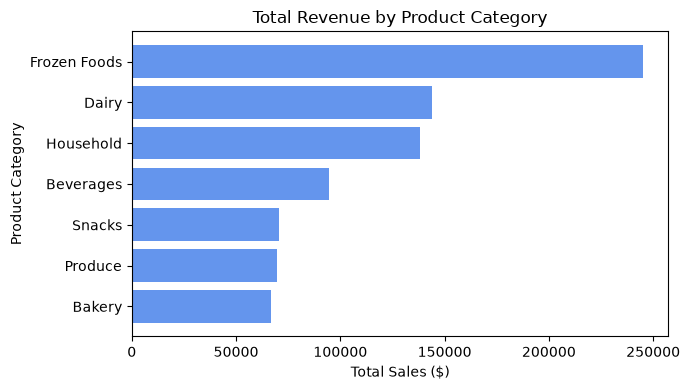

In [67]:
# This is my matplotlib horizontal bar chart using my category performance dataframe
plot_data = category_performance.sort_values(by='Total_Sales', ascending=True) # to make the highest revenue appear at the top of the chart
plt.figure(figsize=(7, 4))
plt.barh(plot_data['Product_Category'], plot_data['Total_Sales'], color='cornflowerblue')

plt.title('Total Revenue by Product Category')
plt.xlabel('Total Sales ($)')
plt.ylabel('Product Category')
plt.tight_layout() # is always used just in case labels are too long so that everything fits
plt.show()

We can see that the frozen foods category generates the highest revenue of the store, followed by the dairy section. Further calculating the average price per unit for each category:

In [48]:
category_performance['Average_Price_Per_Unit'] = (
    category_performance['Total_Sales'] / category_performance['Quantity_Sold']
)
category_performance = category_performance.sort_values(
    by='Average_Price_Per_Unit', ascending=False)
category_performance

,Product_Category,Total_Sales,Quantity_Sold,Average_Price_Per_Unit
3,Frozen Foods,245033.61,1585,154.595338
4,Household,138068.54,1036,133.270792
2,Dairy,143856.08,2313,62.194587
1,Beverages,94411.51,1734,54.447238
0,Bakery,66528.13,1505,44.204738
6,Snacks,70489.82,1926,36.599076
5,Produce,69796.58,2159,32.328198


This shows that despite selling fewer items, it has a higher average price per unit which is how its high revenue is generated. The store can now see that the high revenue categories like frozen foods have a higher value per item ratio. It also shows that whilst produce has a high quantity of items sold, it generates a lower total revenue than the other categories, so the store may want to mark up these prices. This logic can be applied to snacks too, and somewhat to dairy.

### Question 2 - How do total sales and transaction volumes compare across different store locations?

It is worth taking the time to analyse how sales compare across different stores, but also how many transactions have been registered at these stores, as this will give a measure of how busy it is with different people buying different quantities of items. We can do this by grouping by store location, then:

In [50]:
df['Store_Location'] = df['Store_Location'].str.strip().str.title() # I did this as there were some repeat store locations with the same name but
# different capitalisation, e.g. 'Delhi' and 'delhi', when I first ran the below query
store_performance = df.groupby('Store_Location').agg(
    Total_Revenue=('Total_Sales', 'sum'),
    Total_Transactions=('Transaction_ID', 'count'),
    Average_Order_Value=('Total_Sales', 'mean')
).reset_index()
store_performance = store_performance.sort_values(by='Total_Revenue', ascending=False)
store_performance

,Store_Location,Total_Revenue,Total_Transactions,Average_Order_Value
2,Delhi,189312.57,107,1769.276355
1,Chennai,173776.63,85,2044.430941
3,Mumbai,166199.82,109,1524.768991
0,Bangalore,160041.73,97,1649.914742
4,Pune,138853.52,87,1596.017471


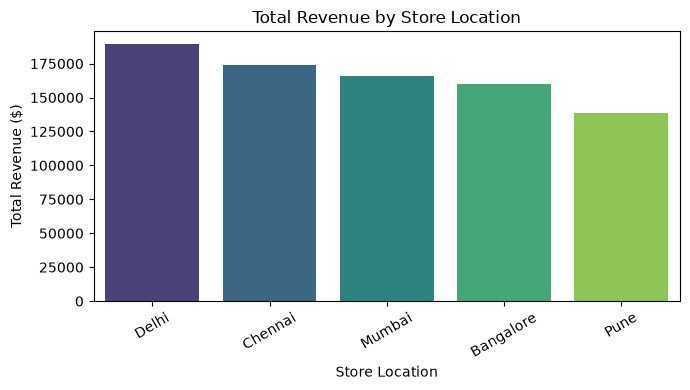

In [68]:
# This is my seaborn bar plot using my store_performance data

plt.figure(figsize=(7, 4))
sns.barplot(
    data=store_performance, 
    x='Store_Location', 
    y='Total_Revenue', 
    palette='viridis', 
    hue='Store_Location', 
    legend=False
)

plt.title('Total Revenue by Store Location')
plt.xlabel('Store Location')
plt.ylabel('Total Revenue ($)')
plt.xticks(rotation=30) # isn't necessary here as they won't overlap but tilts the x axis labels to make them look cleaner
plt.tight_layout()
plt.show()

As we can see here, Delhi's store was the top revenue generator, with a higher total transactions as opposed to a higher average order value driving the high total revenue. Delhi houses the capital city of India, and has the largest population out of all of these groups, in the order of Delhi with the largest, then Mumbai, Bangalore, Chennai, and finally Pune. All this is to say that a large number of transactions for both Delhi and Mumbai are understandable with a larger population of people that can access the store, and with their total revenues weighted towards being driven by this metric as opposed to their lower average order values. Bangalore also follows this pattern as the group's midpoint in transactions and average order value.

From a business perspective, Mumbai has the highest total number of transactions but the lowest average order value, whereas Chennai has the lowest total number of transactions, but the highest order value. This dataframe also tells us that the underperforming store at Pune is lacking in both total transactions and average order value. This gives an area of further assessment that could be done, such as analysing their marketing or promotions offered to increase Pune's and Chennai's number of customers/transactions. To tackle the average order value, you could make promotions require a minimum spend, e.g. spend x to get 5% off, which would help Pune's and Mumbai's stores.

### Question 3 - Does offering or increasing the discount percentage actually affect total sales generated?

It is important for a manager to determine whether their discounts offered are a help or hinderance to their store.

In [56]:
df[['Discount_Percent', 'Unit_Price', 'Total_Sales']].head(5)

,Discount_Percent,Unit_Price,Total_Sales
0,5.0,94.76,450.11
1,2.5,46.41,696.15
2,20.0,29.47,70.73
3,15.0,31.24,451.42
4,5.0,46.30,1407.52


My dataset contains percentages of varying sizes, and with some decimals as indicated by its data type of float and row 1 being 2.5%. I am going to group by discount percent to run my calculations and analysis:

In [57]:
discount_analysis = df.groupby('Discount_Percent').agg(
    Total_Revenue=('Total_Sales', 'sum'),
    Transaction_Count=('Transaction_ID', 'count'),
    Average_Sales=('Total_Sales', 'mean')
).reset_index()
discount_analysis = discount_analysis.sort_values(by='Discount_Percent')
discount_analysis

,Discount_Percent,Total_Revenue,Transaction_Count,Average_Sales
0,0.0,315255.60,178,1771.098876
1,2.5,696.15,1,696.150000
2,5.0,198113.97,117,1693.281795
3,7.5,7632.15,3,2544.050000
4,10.0,161183.40,98,1644.728571
5,12.5,2634.80,1,2634.800000
6,15.0,97710.62,60,1628.510333
7,20.0,44957.58,27,1665.095556


As can be seen, the total revenue and transaction counts are the highest for no discount percentage, which was expected as it should be the case that the majority of your stock is not on sale, especially items that perform well regardless. If we exclude the discounts that are not integers, as those are rarer discounts, something that is an interesting revelation is that as the discount percentage increases, the total revenue and the transaction count decrease. For example, a 5% discount offers a total revenue of almost 200,000 dollars and transaction count of 178, whereas a 20% discount gives us a total revenue of just under 45,000 dollars and a transaction count of 27.

Using these key takeaways, some actions that the business could consider are first of all phasing out their higher tier of discounts, as they appear to be hurting profits whilst not driving transactions high enough. The 5%-10% discounts appear to work the best for the business, so these can remain as a focus. Finally, we have seen in earlier analysis that categories such as frozen foods are the money makers, so in these cases there can be a zero percent or only small discount to maximise profits.

### Question 4 - Which product categories have the highest average customer ratings? And do the higher rated categories correlate to the highest sales?

Feedback is also important in a business. Here we will see what categories have the highest rating from customers and compare this to the previous sales data acquired in question 1.

In [58]:
satisfaction_analysis = df.groupby('Product_Category').agg(
    Average_Rating=('Customer_Rating', 'mean'),
    Median_Rating=('Customer_Rating', 'median'),
    Total_Ratings_Count=('Customer_Rating', 'count'),
    Total_Revenue=('Total_Sales', 'sum')
).reset_index()
satisfaction_analysis = satisfaction_analysis.sort_values(by='Average_Rating', ascending=False)
satisfaction_analysis

,Product_Category,Average_Rating,Median_Rating,Total_Ratings_Count,Total_Revenue
3,Frozen Foods,3.983636,4.00,55,245033.61
2,Dairy,3.843750,3.90,96,143856.08
0,Bakery,3.821818,3.80,55,66528.13
1,Beverages,3.780714,3.90,70,94411.51
6,Snacks,3.780000,3.70,75,70489.82
5,Produce,3.717391,3.70,92,69796.58
4,Household,3.696429,3.75,42,138068.54


This dataframe shows that frozen foods, which was previously listed as the highest earner of all the categories, is also the category with the highest average and median rating. This shows that customers believe in the value and quality in this category, which is useful information to the store as they know not to focus on this category or make harsh changes to the product selection. Dairy is close second, another category that had a strong revenue, and also has the highest total ratings registered, which shows consistent customer approval for this category.

Whilst I would say that there are no severely underperforming categories, as the lowest average rating is almost a 3.7/5 with a median rating of 3.75/5, the categories of household and produce are slightly lagging behind the rest in terms of satisfaction. Household does generate a good amount of revenue, close to Dairy, but this could indicate that the business should check their product quality or conditions, or even what price points they set items at. Produce having the second lowest satisfaction with the second highest total ratings could indicate to the business that there are issues with item freshness or quality. These are two areas that the company can look into further, and finally the company should also prompt customers for more feedback after purchasing from their store, as the overall ratings counts are low, in particular the rating counts for household which may not be enough data to form accurate conclusions with.

### Question 5 - What are the most used payment modes by customers, and do certain payment methods have a higher level of returns?

Due to this dataset containing information about the payment type and if the items were returned or not, both points of data that have not been analysed yet, I wanted to combine both into this final question of what modes are most commonly used by customers, and whether certain payment methods used have higher levels of returns, which is valuable data for a store to retain their income. This is done by aggregating the data based on payment method, and also calculating the return rate as a percentage of the total transactions for each payment option:

In [63]:
df['Returned_Numeric'] = df['Returned'].map({'Yes': 1, 'No': 0, True: 1, False: 0}) # I have to do this first as the column has yes or no strings,
# which I cannot use with an integer like 'Transaction_Count' that counts the rows
payment_analysis = df.groupby('Payment_Mode').agg(
    Total_Revenue=('Total_Sales', 'sum'),
    Transaction_Count=('Transaction_ID', 'count'),
    Total_Returns=('Returned_Numeric', 'sum'),
    Average_Sales=('Total_Sales', 'mean')
).reset_index()
payment_analysis['Return_Rate_%'] = (payment_analysis['Total_Returns'] / payment_analysis['Transaction_Count']) * 100
payment_analysis = payment_analysis.sort_values(by='Transaction_Count', ascending=False)
payment_analysis

,Payment_Mode,Total_Revenue,Transaction_Count,Total_Returns,Average_Sales,Return_Rate_%
3,UPI,224824.22,133,12,1690.407669,9.022556
0,Cash,171923.26,107,5,1606.759439,4.672897
1,Credit Card,192687.12,101,8,1907.793267,7.920792
2,Debit Card,149973.59,88,9,1704.245341,10.227273
4,Wallet,88776.08,56,3,1585.287143,5.357143


*Before analysing, just to explain, a UPI is a Unified Payments Interface, similar to Google Pay that connects a bank account to the merchant's account. A wallet is a prepaid card or account balance from which funds are withdrawn from.*

Looking at the dataframe above, UPI is the most dominant payment mode, with the highest total revenue and highest transaction count, but also has the highest number of total returns. Debit card transactions have the highest return rate, and cash transactions have the lowest return rate (with only 5 returns in 107 transactions), whilst still generating a good revenue of just above 170,000 dollars. Wallet transactions have the lowest revenue, but have the second lowest return rate at 5.36%.

In terms of how this could affect the business, with UPI having the higest revenue and transactions, the terminals used in-store to claim these transactions should always be monitored to ensure there are never any faults. An investigation into the higher return rates for debit cards, maybe looking into the product categories that are highest returned using debit cards, could be looked into. Finally, overall return policies can be looked into, maybe tightening those that use debit cards.